# 🌧️ PrevIA

**FIAP · Global Solution 2026.2 · Engenharia de Software · Inteligência Artificial & Machine Learning**

Integrantes:

```
Ana Clara Melo - RM 559021
David Murillo de Oliveira - RM 559078
Lucas Serrano - RM 555170
Yasmin Gonçalves - RM 559147
```

## 1. O problema e a pergunta de ML

A PrevIA quer ajudar moradores de áreas sujeitas a alagamento e deslizamento a saber com antecedência quando vem uma chuva forte. Pensamos no morador que muitas vezes só percebe o perigo quando a água já está subindo na rua.

Para o ML, a gente transformou isso numa pergunta que os dados conseguem responder:

> **Com o que foi medido hoje na estação meteorológica de São Paulo, vai chover forte amanhã?**

É um problema de **classificação binária**: 1 = chuva forte no dia seguinte, 0 = não.

Definimos "chuva forte" como **20 mm ou mais em um dia**. Esse número é um critério nosso, escolhido para termos exemplos suficientes de cada classe. Não estamos usando um limite oficial de alerta da Defesa Civil, e isso fica registrado como limitação no final.

## 2. Os dados

Usamos dados **reais e públicos** do INMET (Instituto Nacional de Meteorologia).

| | |
|---|---|
| Fonte | INMET, Dados Históricos: https://portal.inmet.gov.br/dadoshistoricos |
| Estação | A701, São Paulo – Mirante de Santana (lat -23,496, lon -46,620) |
| Período | 24/07/2006 a 28/02/2025 |
| Frequência | diária (o INMET mede de hora em hora, a gente trabalha com o resumo do dia) |
| Tamanho | 6.795 dias, 13 variáveis meteorológicas |
| Arquivo | `dados/inmet_A701_sao_paulo_diario.csv` |

**De onde o arquivo veio** pegamos as séries do INMET já convertidas para parquet no repositório público [viniciusoike/inmetr](https://github.com/viniciusoike/inmetr) (release `data-2026-10-24`), conferindo o SHA-256 de cada arquivo com o manifesto do próprio repositório. Filtramos a estação A701 e salvamos em CSV. Quem quiser conferir pode baixar os zips anuais direto no portal do INMET. Mais detalhes em `dados/README.md`.

Variáveis do CSV: temperatura (média, mínima, máxima, ponto de orvalho), umidade relativa (média, mínima, máxima), chuva do dia (mm), radiação, pressão atmosférica, velocidade do vento, rajada máxima e quantas horas de medição o dia teve.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, fbeta_score, confusion_matrix, precision_recall_curve,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline

SEED = 42
LIMIAR_CHUVA_FORTE = 20  # mm em um dia (critério adotado pela equipe)

# cores: azul = treino, laranja = teste (sempre as mesmas nos gráficos)
AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, MUDO, GRADE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2,
    "xtick.color": MUDO, "ytick.color": MUDO, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "savefig.dpi": 150, "savefig.bbox": "tight",
})

PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)
resultados = {}  # vamos guardando os números principais aqui para o relatório

In [ ]:
df = pd.read_csv("dados/inmet_A701_sao_paulo_diario.csv", parse_dates=["date"])
df = df.set_index("date").asfreq("D")   # garante um índice diário sem buracos

print("Linhas:", len(df))
print("Período:", df.index.min().date(), "até", df.index.max().date())
print("Estação:", df["estacao"].dropna().unique())
df.head()

Linhas: 6795
Período: 2006-07-24 até 2025-02-28
Estação: <ArrowStringArray>
['A701']
Length: 1, dtype: str


,estacao,temp_mean_c,temp_min_c,temp_max_c,temp_dew_point_mean_c,rel_humidity_mean_pct,rel_humidity_min_pct,rel_humidity_max_pct,precip_total_mm,radiation_total_kj_m2,pressure_station_mean_hpa,wind_speed_mean_ms,wind_gust_max_ms,n_hours
date,,,,,,,,,,,,,,
2006-07-24,A701,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2006-07-25,A701,24.607692,19.6,27.9,14.315385,53.230769,45.0,70.0,0.0,0.0,925.776923,1.638462,7.2,13
2006-07-26,A701,21.191667,15.6,27.5,13.400000,63.083333,44.0,87.0,0.4,0.0,925.254167,1.612500,10.1,24
2006-07-27,A701,21.391667,14.4,28.2,13.612500,62.958333,42.0,87.0,0.0,0.0,925.191667,1.537500,8.4,24
2006-07-28,A701,22.979167,17.5,29.4,16.516667,68.875000,51.0,98.0,0.0,0.0,924.183333,1.766667,9.1,24


## 3. Conhecendo os dados

Primeiro, uma checagem de qualidade: quanto falta em cada coluna e como a chuva se comporta ao longo dos anos.

In [ ]:
nulos = (df.isna().mean() * 100).round(2).rename("% de valores ausentes")
nulos.to_frame().T

,estacao,temp_mean_c,temp_min_c,temp_max_c,temp_dew_point_mean_c,rel_humidity_mean_pct,rel_humidity_min_pct,rel_humidity_max_pct,precip_total_mm,radiation_total_kj_m2,pressure_station_mean_hpa,wind_speed_mean_ms,wind_gust_max_ms,n_hours
% de valores ausentes,0.0,0.31,0.24,0.24,0.24,0.24,0.24,0.24,0.46,0.28,0.22,0.22,0.22,0.0


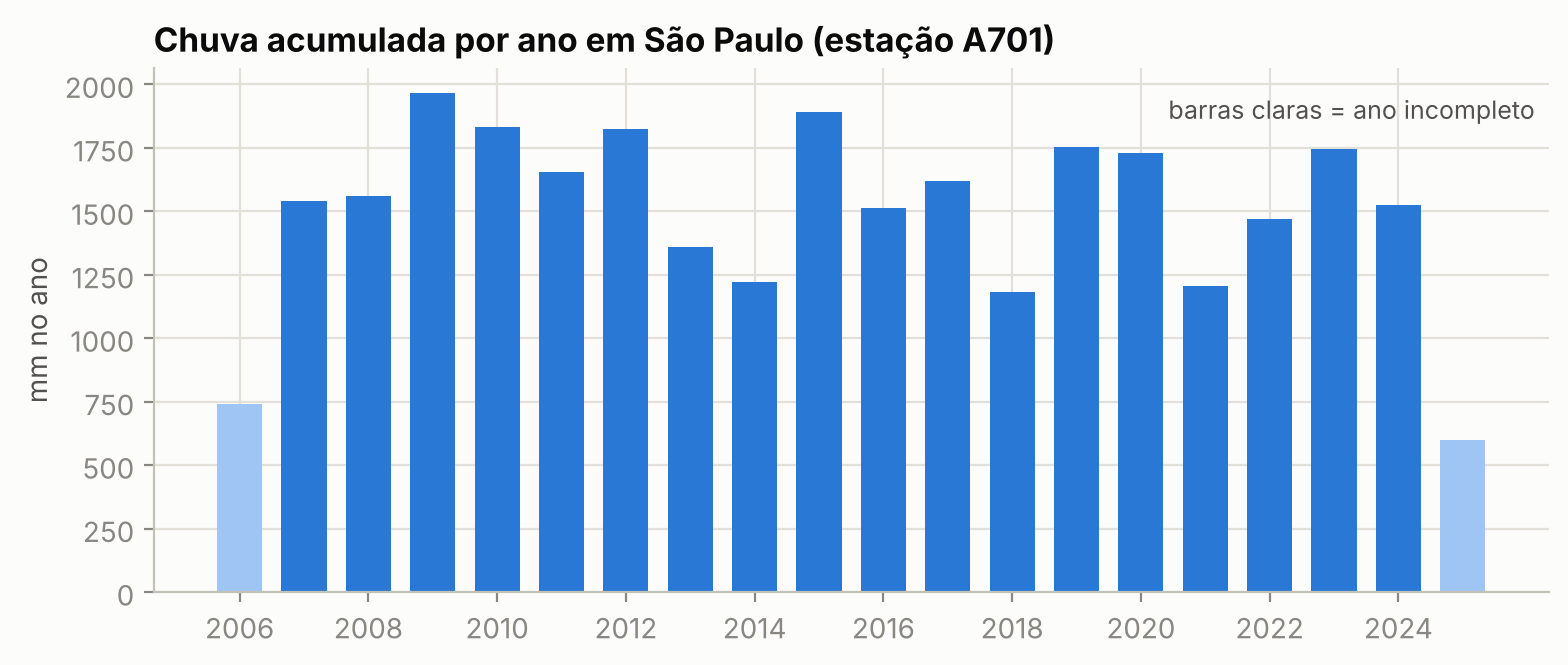

In [ ]:
chuva_ano = df["precip_total_mm"].groupby(df.index.year).sum()
dias_ano = df["precip_total_mm"].groupby(df.index.year).count()

fig, ax = plt.subplots(figsize=(9, 3.4))
parcial = dias_ano < 330   # 2006 e 2025 não têm o ano inteiro
ax.bar(chuva_ano.index[~parcial], chuva_ano[~parcial], color=AZUL, width=0.7)
ax.bar(chuva_ano.index[parcial], chuva_ano[parcial], color="#9ec5f4", width=0.7)
ax.set_title("Chuva acumulada por ano em São Paulo (estação A701)")
ax.set_ylabel("mm no ano")
ax.set_xticks(chuva_ano.index[::2])
ax.text(0.99, 0.95, "barras claras = ano incompleto", transform=ax.transAxes,
        ha="right", va="top", color=TINTA_2, fontsize=9)
fig.savefig(PASTA_FIG / "01_chuva_por_ano.png")
plt.show()

**O que dá para ver aqui:**

- A série está quase completa. Não falta nenhum dia no calendário e as colunas com mais buracos têm no máximo uns 0,5% de valores ausentes (a chuva é a pior delas).
- Os anos completos ficam entre uns 1.200 mm e 2.000 mm de chuva, o que bate com o clima de São Paulo. Isso foi uma boa checagem de sanidade para ver se o dado faz sentido.
- 2006 e 2025 são anos incompletos (começamos em julho de 2006 e a série termina em fevereiro de 2025), por isso as barras claras.

## 4. Quando chove forte?

Antes de treinar qualquer coisa, vale olhar o padrão da chuva forte ao longo do ano.

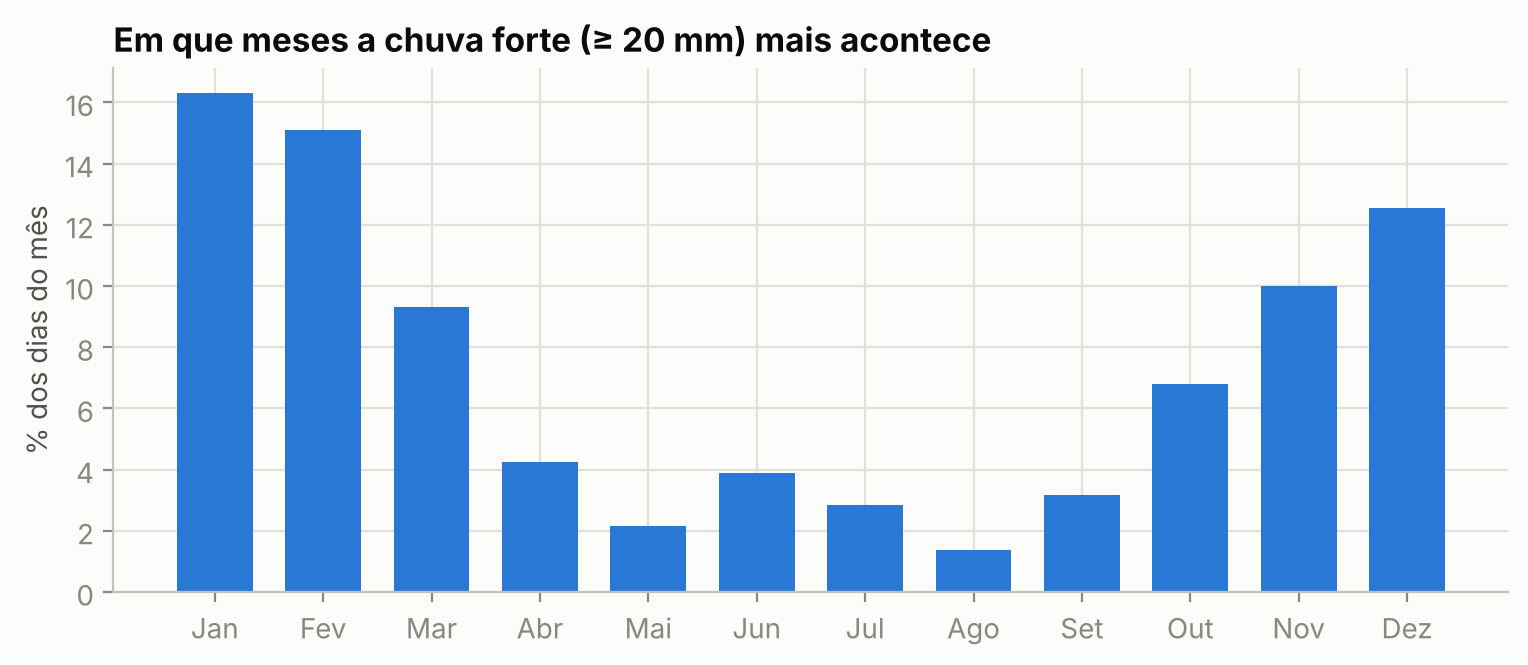

date,1,2,3,4,5,6,7,8,9,10,11,12
chuva_media_mm_dia,9.44,8.80,6.12,2.76,1.70,2.22,1.77,1.25,2.36,4.17,5.06,7.22
pct_dias_chuva_forte,16.30,15.08,9.32,4.26,2.15,3.89,2.83,1.36,3.16,6.79,10.00,12.56


In [ ]:
mes = df.index.month
alvo_hoje = (df["precip_total_mm"] >= LIMIAR_CHUVA_FORTE)
por_mes = pd.DataFrame({
    "chuva_media_mm_dia": df["precip_total_mm"].groupby(mes).mean(),
    "pct_dias_chuva_forte": alvo_hoje.groupby(mes).mean() * 100,
})
nomes = ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(nomes, por_mes["pct_dias_chuva_forte"], color=AZUL, width=0.7)
ax.set_title("Em que meses a chuva forte (≥ 20 mm) mais acontece")
ax.set_ylabel("% dos dias do mês")
fig.savefig(PASTA_FIG / "02_chuva_forte_por_mes.png")
plt.show()

por_mes.round(2).T

A chuva forte é muito sazonal: passa de 15% dos dias em janeiro e fevereiro e fica em torno de 1% a 2% em agosto e maio. Por isso colocamos o mês do ano como variável do modelo, e a gente espera que ele ajude mesmo que não seja o mais importante.

## 5. O que o modelo precisa acertar

O alvo é "choveu 20 mm ou mais **amanhã**". Para cada dia, olhamos a chuva do dia seguinte. O último dia da série fica sem rótulo (não sabemos o que veio depois), então ele sai.

In [ ]:
chuva_amanha = df["precip_total_mm"].shift(-1)          # chuva do dia seguinte
y_all = (chuva_amanha >= LIMIAR_CHUVA_FORTE).astype(float)
y_all[chuva_amanha.isna()] = np.nan                     # sem chuva medida amanhã = sem rótulo

rotulados = y_all.dropna()
print(f"Dias com rótulo: {len(rotulados)}")
print(f"Dias de chuva forte no dia seguinte: {int(rotulados.sum())} ({rotulados.mean()*100:.1f}%)")
print(f"Dias sem chuva forte: {int((1-rotulados).sum())} ({(1-rotulados.mean())*100:.1f}%)")

Dias com rótulo: 6764
Dias de chuva forte no dia seguinte: 498 (7.4%)
Dias sem chuva forte: 6266 (92.6%)


Só cerca de **7 em cada 100 dias** têm chuva forte no dia seguinte. É um problema **desbalanceado**, e isso muda a forma de avaliar o modelo:

- Um modelo que respondesse "não vai chover forte" todos os dias acertaria uns 92% e não serviria para nada, porque nunca avisaria ninguém. Por isso **acurácia não é a métrica principal aqui**.
- Vamos olhar **recall** (das chuvas fortes que aconteceram, quantas o modelo avisou), **precisão** (dos avisos que ele deu, quantos eram verdade), **F1** e a **PR-AUC**, que resume o equilíbrio entre precisão e recall em todos os limiares possíveis.

## 6. Preparação dos dados

Criamos as variáveis (features) usando **só o que já se sabe no fim do dia de hoje**. Nada do futuro entra, senão o modelo estaria colando. Além das medições do dia, montamos algumas variáveis que fazem sentido para chuva:

- **chuva acumulada** nos últimos 3, 7 e 15 dias (solo encharcado piora o efeito de uma chuva nova);
- **variação da pressão** em 1 e 2 dias (queda de pressão costuma anunciar frente fria);
- **amplitude térmica** (máxima menos mínima do dia);
- **mês do ano** em seno e cosseno, para o modelo entender que dezembro fica perto de janeiro.

In [ ]:
def montar_features(d):
    """Cria as variáveis usando só o que já se sabe até o fim do dia de hoje."""
    p = d["precip_total_mm"]
    X = pd.DataFrame(index=d.index)

    # quanto choveu recentemente (solo encharcado piora o efeito de uma chuva nova)
    X["chuva_hoje"]  = p
    X["chuva_ontem"] = p.shift(1)
    X["chuva_3d"]    = p.rolling(3,  min_periods=2).sum()
    X["chuva_7d"]    = p.rolling(7,  min_periods=4).sum()
    X["chuva_15d"]   = p.rolling(15, min_periods=8).sum()

    # temperatura e umidade
    X["temp_media"]  = d["temp_mean_c"]
    X["temp_max"]    = d["temp_max_c"]
    X["amplitude_termica"] = d["temp_max_c"] - d["temp_min_c"]
    X["umidade_media"] = d["rel_humidity_mean_pct"]
    X["umidade_min"]   = d["rel_humidity_min_pct"]
    X["ponto_orvalho"] = d["temp_dew_point_mean_c"]

    # pressão (queda de pressão costuma anunciar frente fria e chuva)
    X["pressao"]      = d["pressure_station_mean_hpa"]
    X["dif_pressao_1d"] = d["pressure_station_mean_hpa"].diff(1)
    X["dif_pressao_2d"] = d["pressure_station_mean_hpa"].diff(2)

    # vento e radiação
    X["vento_medio"] = d["wind_speed_mean_ms"]
    X["rajada_max"]  = d["wind_gust_max_ms"]
    X["radiacao"]    = d["radiation_total_kj_m2"]

    # época do ano, de um jeito que dezembro fica "perto" de janeiro
    m = d.index.month
    X["mes_sen"] = np.sin(2 * np.pi * m / 12)
    X["mes_cos"] = np.cos(2 * np.pi * m / 12)
    return X

X_all = montar_features(df)
mask = y_all.notna()
X, y = X_all[mask], y_all[mask].astype(int)
print("Variáveis:", X.shape[1])
X.describe().T[["count", "mean", "min", "max"]].round(2)

Variáveis: 19


,count,mean,min,max
chuva_hoje,6756.0,4.43,0.00,142.40
chuva_ontem,6750.0,4.42,0.00,142.40
chuva_3d,6752.0,13.27,0.00,177.80
chuva_7d,6750.0,30.98,0.00,285.00
chuva_15d,6746.0,66.36,0.00,410.20
temp_media,6752.0,20.48,7.23,30.97
temp_max,6757.0,26.31,8.50,38.40
amplitude_termica,6757.0,9.57,0.50,20.80
umidade_media,6757.0,69.99,23.92,100.00
umidade_min,6757.0,44.21,9.00,100.00


## 7. Divisão entre treino e teste

Dividimos **pelo tempo**, não de forma aleatória: treino até 31/12/2021, teste de 01/01/2022 em diante. O motivo é que dias seguidos são muito parecidos entre si. Se a gente embaralhasse, o modelo treinaria com o dia 10 e seria testado no dia 11, o que é uma forma de ver o futuro. Dividindo pelo tempo, o teste simula o uso de verdade: o modelo aprende com o passado e é testado em dados que ele nunca viu.

Valores ausentes são preenchidos com a **mediana calculada só no treino**. Isso está dentro do pipeline, então a mediana nunca "enxerga" o conjunto de teste.

In [ ]:
DATA_CORTE = "2022-01-01"
treino = X.index < DATA_CORTE
X_tr, y_tr = X[treino],  y[treino]
X_te, y_te = X[~treino], y[~treino]

divisao = pd.DataFrame({
    "início": [X_tr.index.min().date(), X_te.index.min().date()],
    "fim":    [X_tr.index.max().date(), X_te.index.max().date()],
    "dias":   [len(X_tr), len(X_te)],
    "chuvas fortes": [int(y_tr.sum()), int(y_te.sum())],
    "% chuva forte": [round(y_tr.mean()*100, 1), round(y_te.mean()*100, 1)],
}, index=["treino", "teste"])
resultados["divisao"] = {
    "dias_treino": len(X_tr), "dias_teste": len(X_te),
    "fortes_treino": int(y_tr.sum()), "fortes_teste": int(y_te.sum()),
    "prev_treino": float(y_tr.mean()), "prev_teste": float(y_te.mean()),
}
divisao

,início,fim,dias,chuvas fortes,% chuva forte
treino,2006-07-24,2021-12-31,5627,410,7.3
teste,2022-01-01,2025-02-27,1137,88,7.7


O treino tem 5.627 dias (410 com chuva forte no dia seguinte) e o teste tem 1.137 dias (88 com chuva forte). As proporções são parecidas (7,3% e 7,7%), então o teste é um retrato justo do treino. O ponto de atenção é que **88 eventos é pouco**, e isso vai pesar na hora de interpretar as diferenças pequenas entre modelos.

## 8. Por que Random Forest

Escolhemos o **Random Forest** (floresta aleatória) pelos motivos abaixo:

- os dados são uma tabela com poucas variáveis numéricas, que é onde árvores funcionam bem;
- não precisa normalizar as variáveis e captura relações que não são lineares (por exemplo, chuva só vem quando a umidade e a pressão estão em certa combinação);
- tem o parâmetro `class_weight`, que ajuda com classes desbalanceadas (usamos `balanced_subsample`);
- dá para medir a importância das variáveis, o que ajuda a explicar o resultado para o cidadão.

Também consideramos XGBoost e redes neurais, mas com ~5.600 linhas de treino e um sinal fraco nos dados, um modelo mais complicado teria muito mais chance de decorar do que de aprender.

Os três hiperparâmetros que vamos variar:

| Hiperparâmetro | O que controla |
|---|---|
| `n_estimators` | quantas árvores a floresta tem |
| `max_depth` | até que profundidade cada árvore pode crescer (mais fundo = mais chance de decorar) |
| `min_samples_leaf` | mínimo de dias em cada folha da árvore (folha maior = árvore mais conservadora) |

## 9. Contra o que vamos comparar?

Um número de métrica sozinho não diz muito. Antes de treinar, definimos duas referências bem simples, calculadas no conjunto de teste:

1. **Sempre "não"**: nunca avisa ninguém.
2. **Repetir hoje**: avisa que vai chover forte amanhã se choveu forte hoje (a regra que muita gente usa no dia a dia).

Se o modelo não ganhar delas, não valeu a pena.

In [ ]:
def metricas(y_real, proba, limiar=0.5):
    """Métricas de classificação para o problema de chuva forte."""
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    return {
        "recall": recall_score(y_real, pred),
        "precisao": precision_score(y_real, pred, zero_division=0),
        "f1": f1_score(y_real, pred),
        "pr_auc": average_precision_score(y_real, proba),
        "roc_auc": roc_auc_score(y_real, proba),
        "VP": int(tp), "FP": int(fp), "FN": int(fn), "VN": int(tn),
    }

# Referências simples para comparar com o modelo, no conjunto de teste
base_sempre_nao = metricas(y_te, np.zeros(len(y_te)))
base_persistencia = metricas(y_te, (X_te["chuva_hoje"].fillna(0) >= LIMIAR_CHUVA_FORTE).astype(float))
base_persistencia["pr_auc"] = average_precision_score(y_te, X_te["chuva_hoje"].fillna(0))
base_persistencia["roc_auc"] = roc_auc_score(y_te, X_te["chuva_hoje"].fillna(0))

pd.DataFrame({"sempre diz 'não vai chover forte'": base_sempre_nao,
              "repete o dia de hoje": base_persistencia}).T.round(3)

,recall,precisao,f1,pr_auc,roc_auc,VP,FP,FN,VN
sempre diz 'não vai chover forte',0.000,0.000,0.000,0.077,0.5,0.0,0.0,88.0,1049.0
repete o dia de hoje,0.227,0.227,0.227,0.178,0.7,20.0,68.0,68.0,981.0


A regra "repetir hoje" acerta o recall e a precisão em 23%, com PR-AUC de 0,178. "Sempre não" tem recall zero e a PR-AUC dela (0,077) é só a taxa de dias com chuva forte, ou seja, o que se consegue **no chute**. Essas são as marcas a superar: **PR-AUC > 0,178** para ser melhor que a regra simples.

## 10. Treino com diferentes hiperparâmetros

Testamos **18 combinações** (2 valores de `n_estimators` × 3 de `max_depth` × 3 de `min_samples_leaf`), bem acima das 10 pedidas.

Cada combinação foi avaliada com **validação cruzada em ordem de tempo** (`TimeSeriesSplit`, 5 partes), **só dentro do conjunto de treino**. O teste não é tocado até o final. A métrica de escolha é a **PR-AUC**, por causa do desbalanceamento.

In [ ]:
pipe = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),   # medianas calculadas só no treino
    ("rf", RandomForestClassifier(class_weight="balanced_subsample",
                                  random_state=SEED, n_jobs=-1)),
])

grade = {
    "rf__n_estimators":     [100, 300],
    "rf__max_depth":        [3, 6, None],
    "rf__min_samples_leaf": [1, 5, 20],
}
print("Combinações testadas:", 2 * 3 * 3)

cv = TimeSeriesSplit(n_splits=5)   # validação cruzada respeitando a ordem do tempo, só dentro do treino
busca = GridSearchCV(pipe, grade, cv=cv, scoring="average_precision",
                     n_jobs=-1, return_train_score=True, refit=True)
busca.fit(X_tr, y_tr)

print("Melhor combinação:", {k.replace("rf__", ""): v for k, v in busca.best_params_.items()})
print(f"PR-AUC média na validação cruzada: {busca.best_score_:.3f}")

Combinações testadas: 18


Melhor combinação: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 300}
PR-AUC média na validação cruzada: 0.185


In [ ]:
res = pd.DataFrame(busca.cv_results_)
res["n_arvores"] = res["param_rf__n_estimators"]
res["prof_max"]  = res["param_rf__max_depth"].astype(object).where(res["param_rf__max_depth"].notna(), "sem limite")
res["min_folha"] = res["param_rf__min_samples_leaf"]
res = res.rename(columns={"mean_train_score": "PR-AUC treino", "mean_test_score": "PR-AUC validação"})
res["diferença"] = res["PR-AUC treino"] - res["PR-AUC validação"]
tabela = (res[["n_arvores", "prof_max", "min_folha", "PR-AUC treino", "PR-AUC validação", "diferença"]]
          .sort_values("PR-AUC validação", ascending=False).reset_index(drop=True))
tabela.index = tabela.index + 1
resultados["grid"] = tabela.round(4).astype(str).to_dict(orient="records")
tabela.round(3)

,n_arvores,prof_max,min_folha,PR-AUC treino,PR-AUC validação,diferença
1,300,sem limite,20,0.653,0.185,0.467
2,100,sem limite,20,0.645,0.183,0.462
3,300,6,20,0.459,0.182,0.278
4,300,3,20,0.282,0.180,0.102
5,100,3,20,0.279,0.179,0.099
6,100,6,20,0.452,0.179,0.272
7,300,3,1,0.286,0.177,0.109
8,300,3,5,0.283,0.176,0.107
9,100,6,5,0.513,0.174,0.339
10,300,sem limite,5,0.999,0.174,0.825


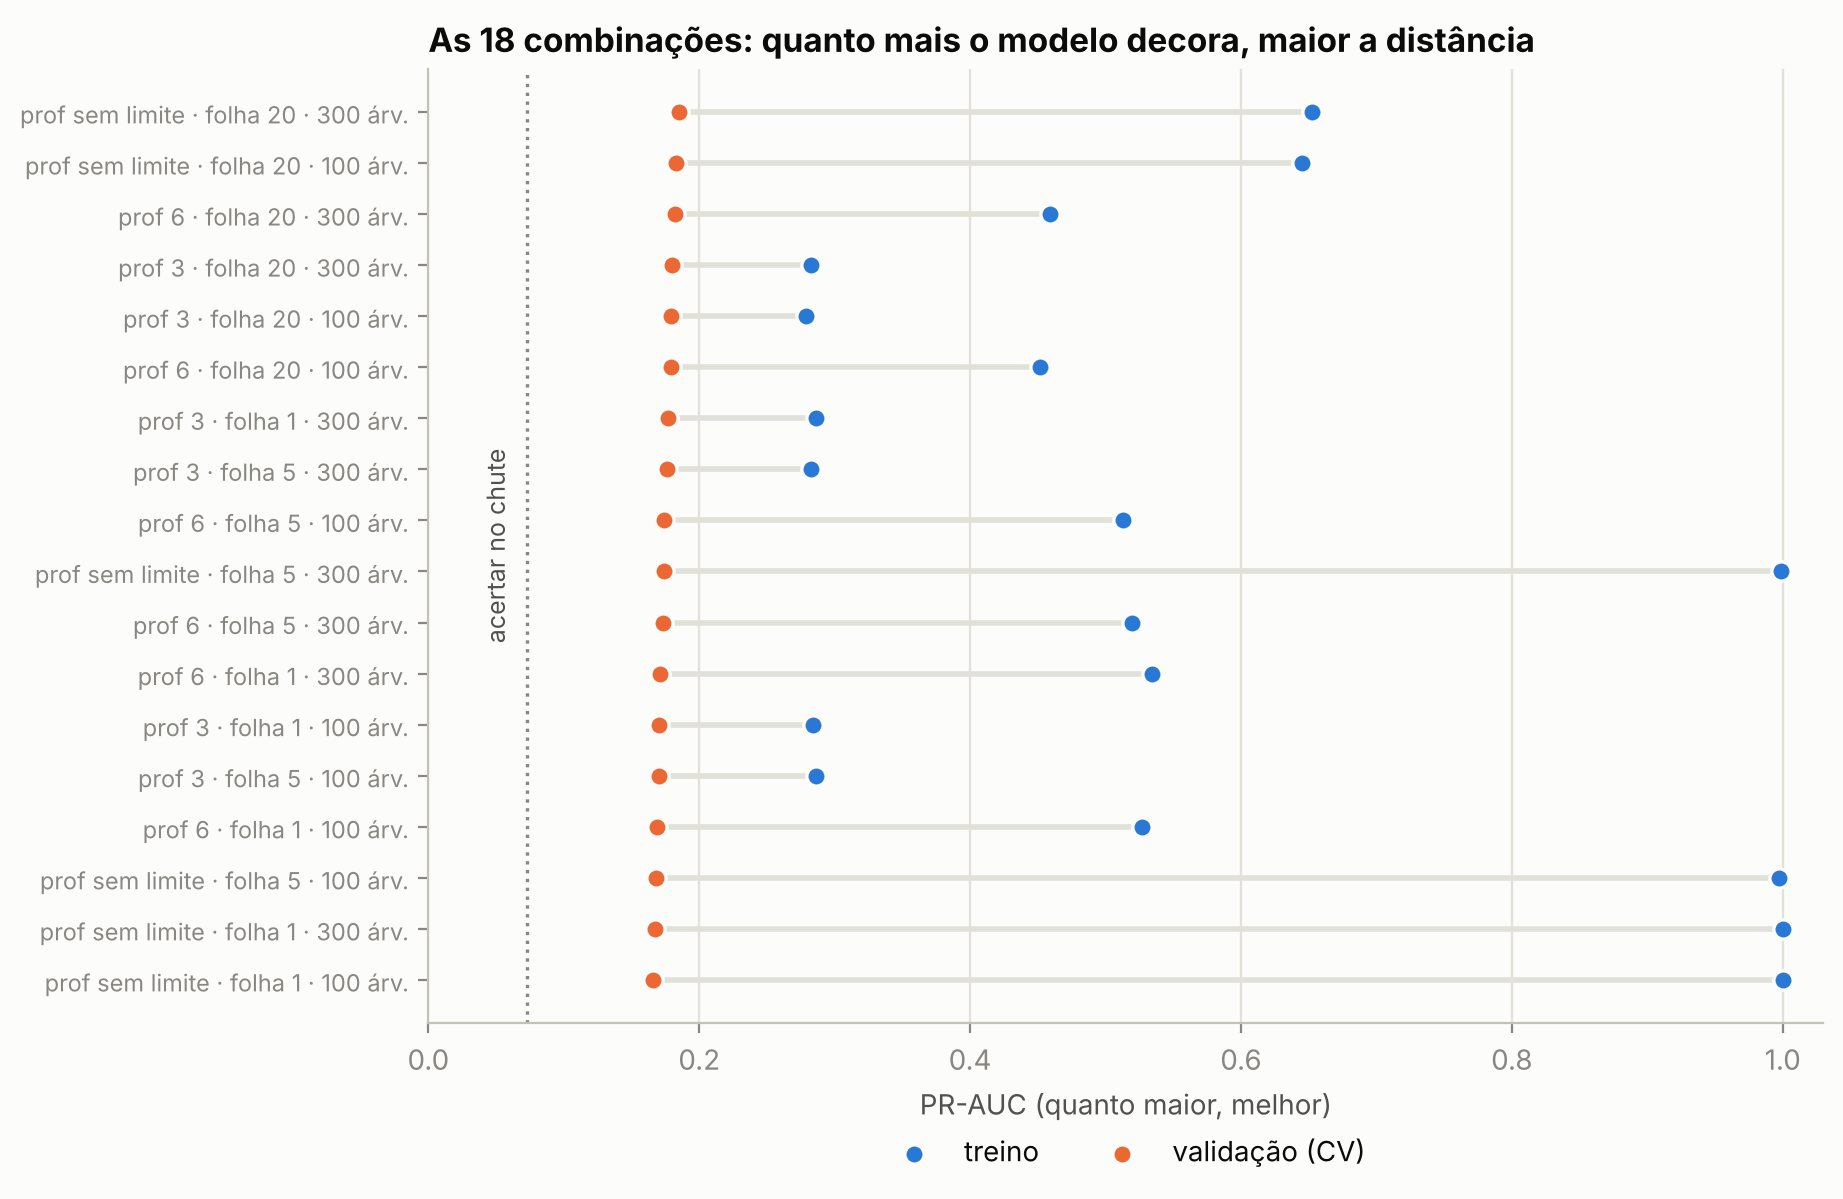

In [ ]:
t = tabela.sort_values("PR-AUC validação")
rotulos = [f"prof {p} · folha {f} · {n} árv." for p, f, n in zip(t["prof_max"], t["min_folha"], t["n_arvores"])]
ypos = np.arange(len(t))

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.hlines(ypos, t["PR-AUC validação"], t["PR-AUC treino"], color=GRADE, linewidth=2, zorder=1)
ax.scatter(t["PR-AUC treino"], ypos, color=AZUL, s=48, label="treino", zorder=3,
           edgecolor="#fcfcfb", linewidth=1.2)
ax.scatter(t["PR-AUC validação"], ypos, color=LARANJA, s=48, label="validação (CV)", zorder=3,
           edgecolor="#fcfcfb", linewidth=1.2)
ax.axvline(y_tr.mean(), color=MUDO, linestyle=":", linewidth=1.2)
ax.text(y_tr.mean() - 0.012, 8.5, "acertar no chute", color=TINTA_2, fontsize=9,
        rotation=90, ha="right", va="center")
ax.set_xlim(0.0, 1.03)
ax.set_yticks(ypos)
ax.set_yticklabels(rotulos, fontsize=8.5)
ax.set_xlabel("PR-AUC (quanto maior, melhor)")
ax.set_title("As 18 combinações: quanto mais o modelo decora, maior a distância")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2)
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIG / "03_combinacoes_treino_vs_validacao.png")
plt.show()

**O que esse gráfico mostra:** para cada combinação, o ponto azul é o desempenho no próprio treino e o laranja é na validação (dados que aquela rodada não viu). Quanto mais comprido o traço, mais o modelo decorou.

- As árvores **sem limite de profundidade** com folhas pequenas chegam a **1,00** de PR-AUC no treino e caem para ~0,17 na validação. É overfitting clássico: o modelo gravou os dias do treino.
- As árvores rasas (profundidade 3) têm desempenho parecido na validação (~0,18) com uma distância bem menor entre treino e validação.
- `min_samples_leaf = 20` foi melhor em todas as profundidades. Folhas maiores deixam a árvore mais conservadora.
- Mais árvores (100 → 300) mudou muito pouco.

A diferença entre a melhor e a pior combinação na validação é pequena (0,185 contra 0,166). Ou seja, o ajuste de hiperparâmetros ajuda, mas não faz milagre: o limite está mais na informação que os dados têm do que no modelo.

A melhor pela regra que definimos foi **n_estimators = 300, max_depth = sem limite, min_samples_leaf = 20**, com PR-AUC de validação ≈ 0,185. Seguimos a regra e ficamos com ela, mas na seção 15 voltamos a comparar com um modelo mais raso.

## 11. Resultados: treino e teste lado a lado

Agora sim usamos o conjunto de teste, uma única vez, com o modelo escolhido na validação. O limiar de decisão por enquanto é o padrão, 0,5 (avisa se a probabilidade for 50% ou mais).

In [ ]:
modelo = busca.best_estimator_
p_tr = modelo.predict_proba(X_tr)[:, 1]
p_te = modelo.predict_proba(X_te)[:, 1]

m_tr = metricas(y_tr, p_tr)
m_te = metricas(y_te, p_te)
resultados["modelo_05"] = {"treino": m_tr, "teste": m_te}
resultados["melhor_params"] = {k.replace("rf__", ""): v for k, v in busca.best_params_.items()}
resultados["cv_pr_auc"] = float(busca.best_score_)
resultados["base_sempre_nao"] = base_sempre_nao
resultados["base_persistencia"] = base_persistencia

lado_a_lado = pd.DataFrame({"treino": m_tr, "teste": m_te}).loc[
    ["recall", "precisao", "f1", "pr_auc", "roc_auc"]].round(3)
lado_a_lado

,treino,teste
recall,0.878,0.523
precisao,0.344,0.191
f1,0.495,0.280
pr_auc,0.713,0.254
roc_auc,0.955,0.773


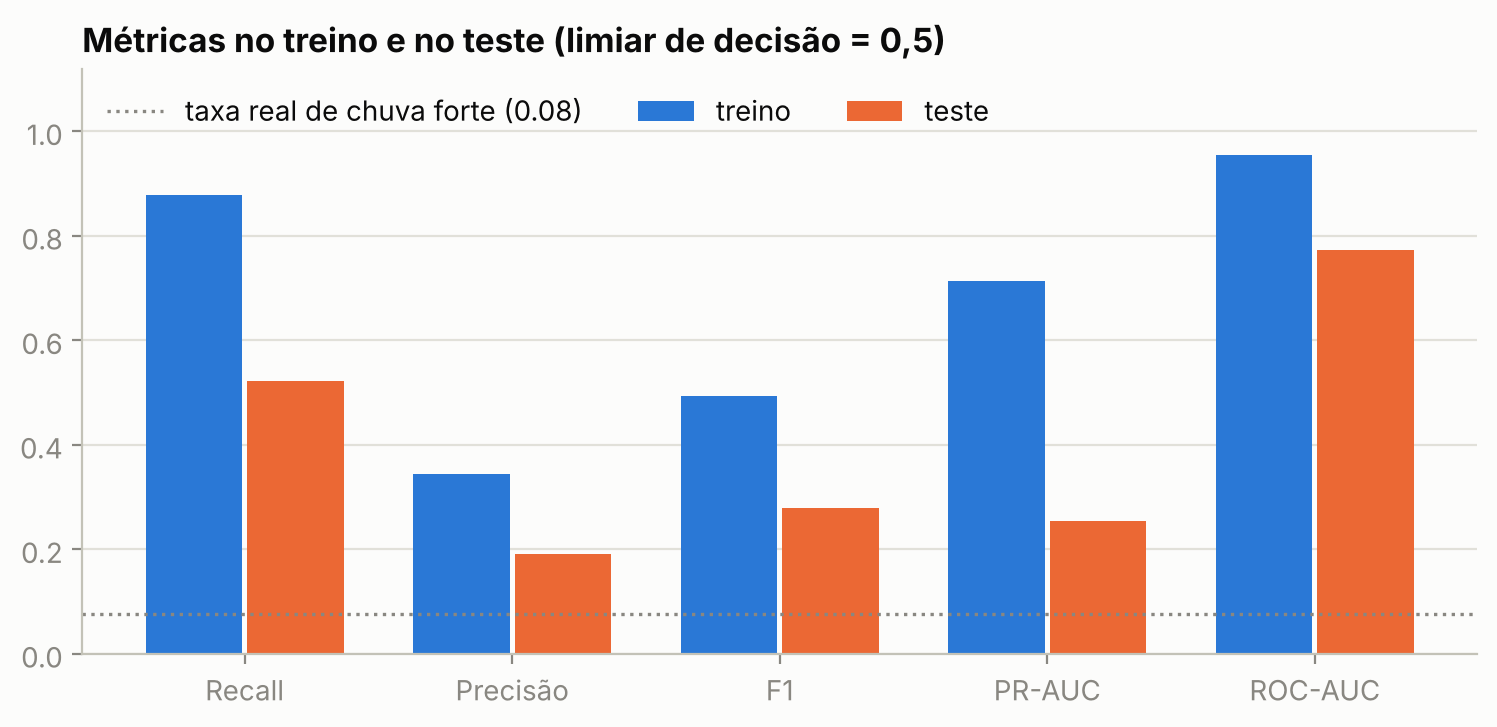

In [ ]:
ordem = ["recall", "precisao", "f1", "pr_auc", "roc_auc"]
nomes_m = ["Recall", "Precisão", "F1", "PR-AUC", "ROC-AUC"]
x = np.arange(len(ordem)); w = 0.36

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(x - w/2 - 0.01, [m_tr[k] for k in ordem], w, color=AZUL, label="treino")
ax.bar(x + w/2 + 0.01, [m_te[k] for k in ordem], w, color=LARANJA, label="teste")
ax.axhline(y_te.mean(), color=MUDO, linestyle=":", linewidth=1.2,
           label=f"taxa real de chuva forte ({y_te.mean():.2f})")
ax.set_xticks(x); ax.set_xticklabels(nomes_m)
ax.set_ylim(0, 1.12)
ax.set_title("Métricas no treino e no teste (limiar de decisão = 0,5)")
ax.legend(loc="upper left", ncol=3)
ax.grid(axis="x", visible=False)
fig.savefig(PASTA_FIG / "04_metricas_treino_vs_teste.png")
plt.show()

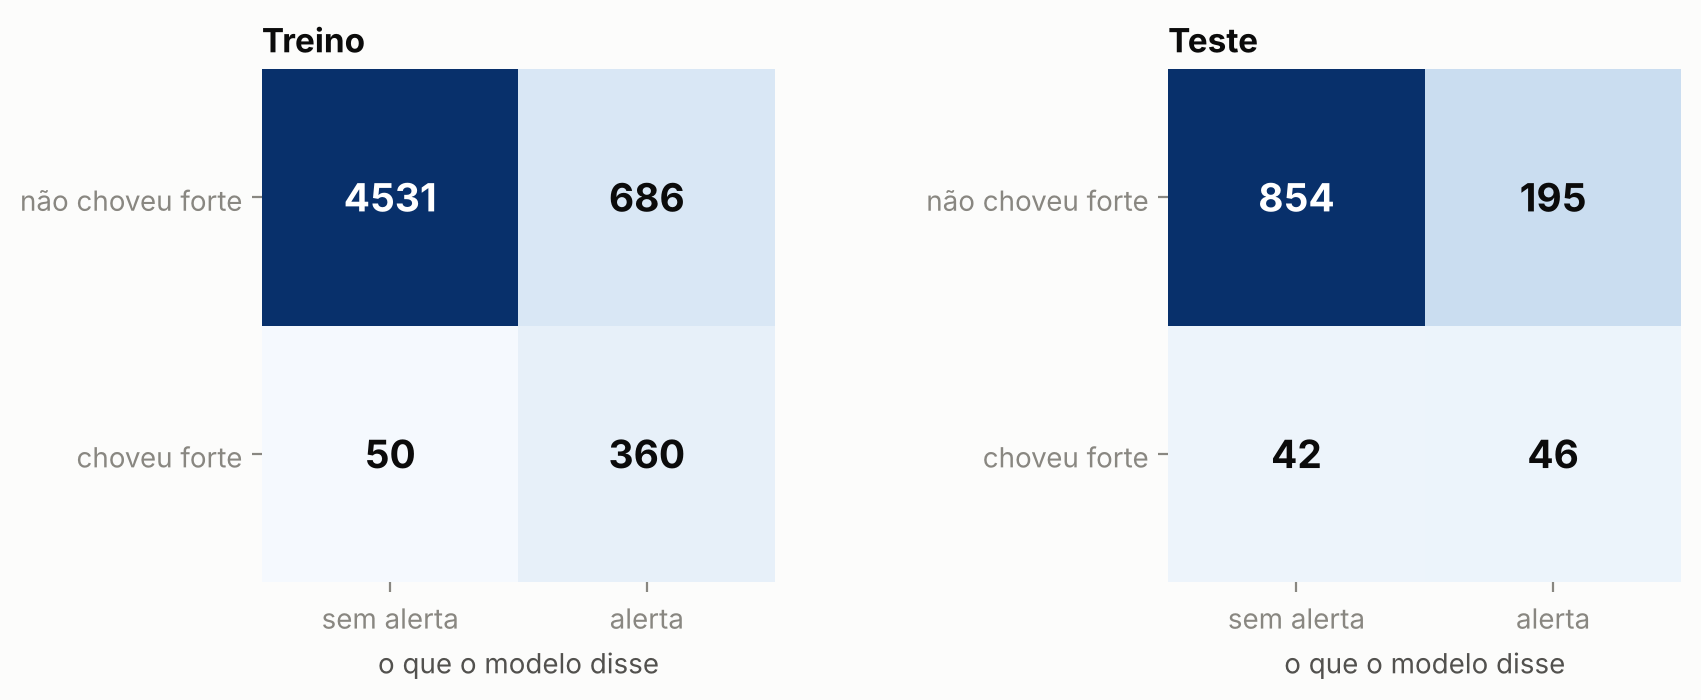

In [ ]:
def plot_cm(ax, y_real, proba, limiar, titulo):
    pred = (proba >= limiar).astype(int)
    cm = confusion_matrix(y_real, pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())
    ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=14, fontweight="bold",
                    color="white" if cm[i, j] > cm.max() * 0.55 else TINTA)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["sem alerta", "alerta"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["não choveu forte", "choveu forte"])
    ax.set_xlabel("o que o modelo disse"); ax.set_title(titulo)
    for s in ax.spines.values(): s.set_visible(False)

fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
plot_cm(axs[0], y_tr, p_tr, 0.5, "Treino")
plot_cm(axs[1], y_te, p_te, 0.5, "Teste")
fig.tight_layout()
fig.savefig(PASTA_FIG / "05_matrizes_de_confusao.png")
plt.show()

**Leitura dos resultados (limiar 0,5):**

| | Recall | Precisão | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Treino | 0,88 | 0,34 | 0,49 | 0,71 | 0,95 |
| Teste | 0,52 | 0,19 | 0,28 | 0,25 | 0,77 |

- **O modelo é melhor que as referências, mas não por muito.** No teste, a PR-AUC é 0,254, contra 0,178 da regra "repetir hoje" e 0,077 do chute. Ou seja, ele consegue avisar de chuva forte com uma qualidade que é uns **3 vezes melhor que o acaso**, mas está longe de ser um oráculo.
- **Treino e teste são bem diferentes.** O recall cai de 0,88 para 0,52 e a PR-AUC de 0,71 para 0,25. Esse é o overfitting aparecendo nos números, e combina com o que vimos no gráfico das combinações.
- **Matriz de confusão do teste:** de 88 chuvas fortes, o modelo avisou **46** e deixou passar **42**. Em compensação, deu **195 alarmes falsos** em 1.049 dias sem chuva forte.
- Mesmo nos dados que ele nunca viu, a ROC-AUC de 0,77 mostra que o modelo separa razoavelmente dias de risco de dias tranquilos.

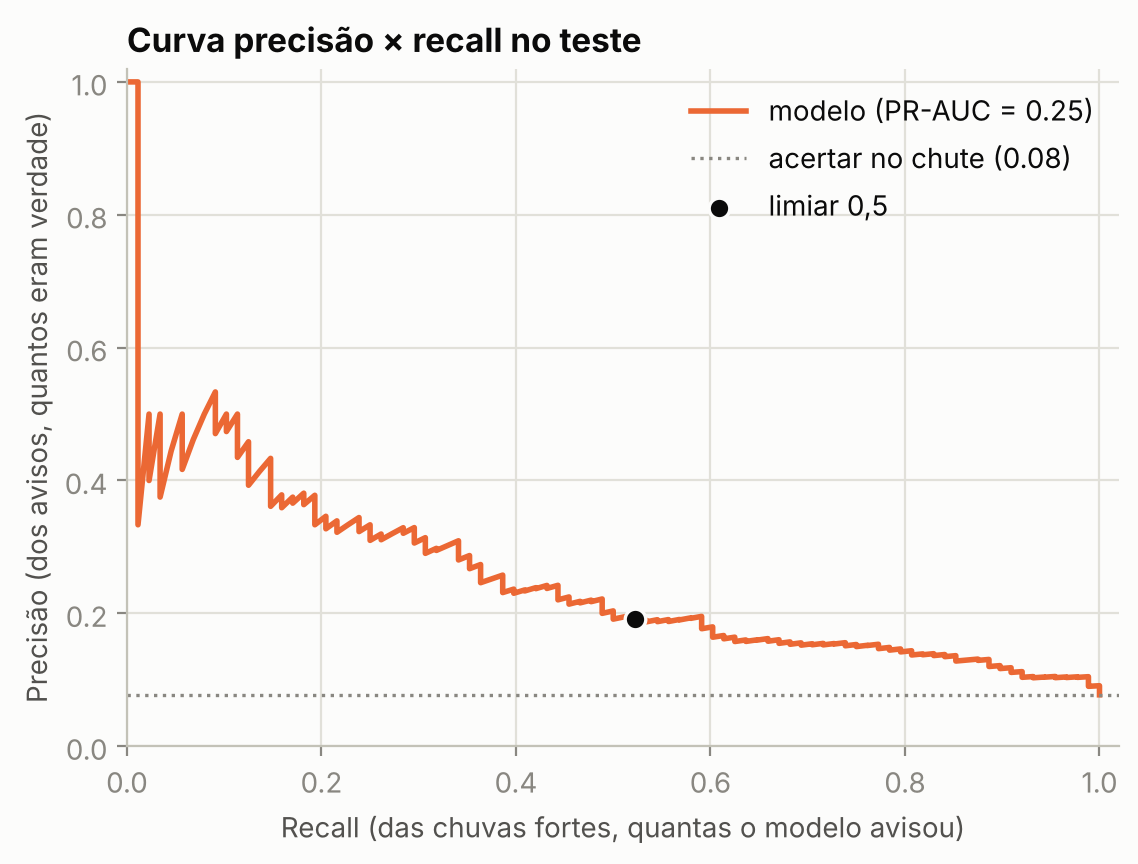

In [ ]:
prec, rec, _ = precision_recall_curve(y_te, p_te)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.plot(rec, prec, color=LARANJA, linewidth=2, label=f"modelo (PR-AUC = {m_te['pr_auc']:.2f})")
ax.axhline(y_te.mean(), color=MUDO, linestyle=":", linewidth=1.2, label=f"acertar no chute ({y_te.mean():.2f})")
ax.scatter([m_te["recall"]], [m_te["precisao"]], color=TINTA, s=55, zorder=4,
           edgecolor="#fcfcfb", linewidth=1.2, label="limiar 0,5")
ax.set_xlabel("Recall (das chuvas fortes, quantas o modelo avisou)")
ax.set_ylabel("Precisão (dos avisos, quantos eram verdade)")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
ax.set_title("Curva precisão × recall no teste")
ax.legend(loc="upper right")
fig.savefig(PASTA_FIG / "06_curva_precisao_recall.png")
plt.show()

A curva mostra o preço de cada escolha. Quanto mais chuvas fortes a gente quer pegar (mais para a direita), menos confiáveis ficam os avisos (mais para baixo). Com o limiar 0,5 (ponto preto) pegamos metade das chuvas com uns 19% de acerto nos avisos. Repare que a curva quase sempre fica acima da linha pontilhada (o acerto no chute), o que confirma que existe sinal nos dados.

A pergunta é qual ponto da curva faz mais sentido para o cidadão. É o que fazemos a seguir.

## 12. Escolhendo o limiar de alerta

Para alerta de enchente, **deixar passar uma chuva forte é pior do que dar um alarme falso**. Então faz sentido abaixar o limiar de 0,5 para pegar mais chuvas, aceitando mais alarmes falsos.

Para não escolher o limiar "olhando a resposta", usamos previsões fora da amostra geradas **dentro do próprio treino** (mesma validação em ordem de tempo) e procuramos o limiar que maximiza o **F2**, uma média entre precisão e recall que dá mais peso ao recall. O teste só entra depois, para ver o que acontece.

In [ ]:
# Escolhendo o limiar SEM olhar o teste: usamos previsões "fora da amostra"
# geradas dentro do próprio treino, com a mesma validação em ordem de tempo.
oof_prob, oof_y = [], []
for idx_a, idx_b in TimeSeriesSplit(n_splits=5).split(X_tr):
    m = clone(busca.best_estimator_).fit(X_tr.iloc[idx_a], y_tr.iloc[idx_a])
    oof_prob.append(m.predict_proba(X_tr.iloc[idx_b])[:, 1])
    oof_y.append(y_tr.iloc[idx_b].values)
oof_prob, oof_y = np.concatenate(oof_prob), np.concatenate(oof_y)

# F2 dá mais peso ao recall: para alerta de enchente, perder uma chuva forte custa mais que um alarme falso
candidatos = np.arange(0.10, 0.90, 0.01)
f2 = [fbeta_score(oof_y, (oof_prob >= t).astype(int), beta=2) for t in candidatos]
limiar_escolhido = float(candidatos[int(np.argmax(f2))])
print(f"Limiar escolhido (máx. F2 na validação do treino): {limiar_escolhido:.2f}")

linhas = {}
for nome, t in [("0,50 (padrão)", 0.5), ("0,30", 0.3), (f"{limiar_escolhido:.2f} (escolhido)", limiar_escolhido)]:
    r = metricas(y_te, p_te, t)
    linhas[nome] = {"recall": r["recall"], "precisao": r["precisao"], "f1": r["f1"],
                    "alertas": r["VP"] + r["FP"], "acertos": r["VP"], "alarmes falsos": r["FP"], "chuvas perdidas": r["FN"]}
resultados["limiar_escolhido"] = limiar_escolhido
resultados["limiares_teste"] = linhas
pd.DataFrame(linhas).T.round(3)

Limiar escolhido (máx. F2 na validação do treino): 0.37


,recall,precisao,f1,alertas,acertos,alarmes falsos,chuvas perdidas
"0,50 (padrão)",0.523,0.191,0.280,241.0,46.0,195.0,42.0
"0,30",0.807,0.138,0.235,516.0,71.0,445.0,17.0
0.37 (escolhido),0.739,0.156,0.257,418.0,65.0,353.0,23.0


O limiar escolhido foi **0,37**. No teste:

| Limiar | Alertas | Acertos | Alarmes falsos | Chuvas perdidas | Recall | Precisão |
|---|---|---|---|---|---|---|
| 0,50 | 241 | 46 | 195 | 42 | 0,52 | 0,19 |
| **0,37 (escolhido)** | 418 | 65 | 353 | 23 | 0,74 | 0,16 |
| 0,30 | 516 | 71 | 445 | 17 | 0,81 | 0,14 |

Com 0,37 o modelo avisa de **74% das chuvas fortes** (65 de 88), mas só **16% dos avisos** são verdadeiros. Cada ponto que a gente ganha de recall custa muitos alarmes falsos. Não existe limiar mágico: é uma escolha de quanto incômodo vale a pena aceitar para perder menos eventos.

## 13. O que o modelo olha para decidir?

Medimos a importância de cada variável com **permutation importance** no conjunto de teste: a gente embaralha uma variável por vez e vê o quanto a PR-AUC piora. Se piora muito, o modelo dependia dela. As linhas cinzas são o desvio entre 15 repetições.

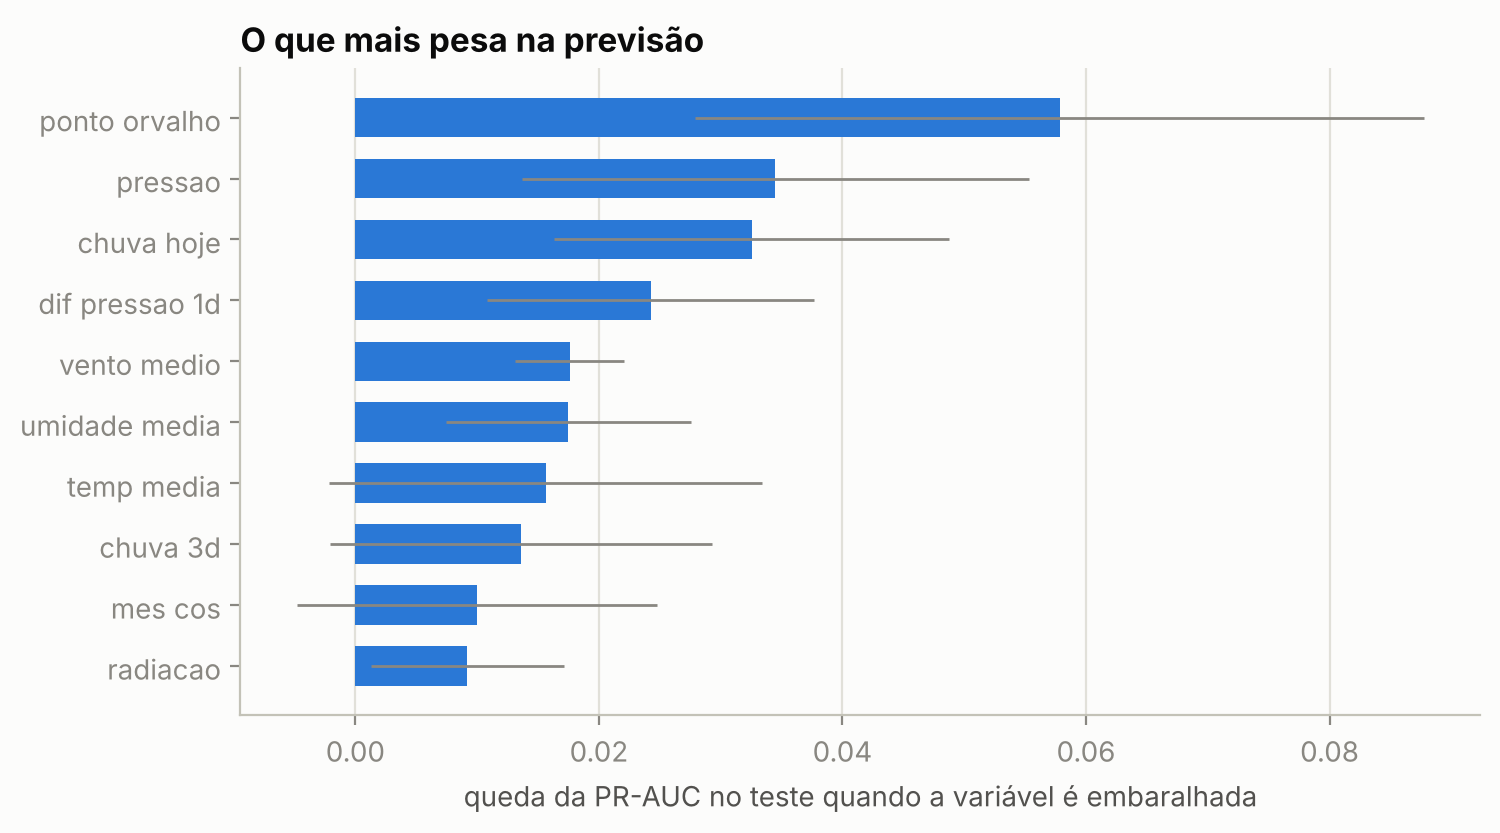

,variavel,queda_pr_auc,desvio
0,ponto_orvalho,0.0578,0.0299
1,pressao,0.0345,0.0208
2,chuva_hoje,0.0325,0.0162
3,dif_pressao_1d,0.0242,0.0135
4,vento_medio,0.0176,0.0045
5,umidade_media,0.0175,0.0101
6,temp_media,0.0156,0.0178
7,chuva_3d,0.0136,0.0157
8,mes_cos,0.0100,0.0148
9,radiacao,0.0092,0.0079


In [ ]:
imp = permutation_importance(modelo, X_te, y_te, scoring="average_precision",
                            n_repeats=15, random_state=SEED, n_jobs=-1)
imp_df = (pd.DataFrame({"variavel": X_te.columns, "queda_pr_auc": imp.importances_mean,
                        "desvio": imp.importances_std})
          .sort_values("queda_pr_auc", ascending=False))
top = imp_df.head(10).iloc[::-1].copy()
top["variavel"] = top["variavel"].str.replace("_", " ")
resultados["importancia_top10"] = imp_df.head(10).round(4).to_dict(orient="records")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top["variavel"], top["queda_pr_auc"], xerr=top["desvio"], color=AZUL, height=0.65,
        error_kw={"ecolor": MUDO, "elinewidth": 1})
ax.set_xlabel("queda da PR-AUC no teste quando a variável é embaralhada")
ax.set_title("O que mais pesa na previsão")
ax.grid(axis="y", visible=False)
fig.savefig(PASTA_FIG / "07_importancia_variaveis.png")
plt.show()
imp_df.head(10).round(4).reset_index(drop=True)

No topo ficaram o **ponto de orvalho**, a **pressão atmosférica**, a **chuva de hoje** e a **variação da pressão em 1 dia**. Isso faz sentido fisicamente: ponto de orvalho alto significa ar carregado de umidade, e a pressão e a variação dela acompanham a chegada de sistemas de chuva. Mas é bom ter cuidado com essa leitura:

- as barras de erro são grandes, então **a ordem entre as primeiras variáveis não é firme**. O que dá para dizer é que umidade/ponto de orvalho e pressão pesam mais do que, por exemplo, a radiação;
- importância não é causa. O modelo usa essas variáveis porque elas se associam à chuva nos dados, não porque provamos que elas a provocam.

## 14. O que isso significa para quem mora na área de risco?

Vamos traduzir os números para a vida real, usando o limiar de 0,37 nos 3,2 anos do período de teste.

In [ ]:
# Como isso ficaria para quem mora numa área de risco, no período do teste
teste = X_te.copy()
teste["prob"] = p_te
teste["real"] = y_te.values
teste["alerta"] = (teste["prob"] >= limiar_escolhido).astype(int)

anos = (teste.index.max() - teste.index.min()).days / 365.25
n_alerta = int(teste["alerta"].sum())
n_ok = int(((teste["alerta"] == 1) & (teste["real"] == 1)).sum())
n_falso = n_alerta - n_ok
n_perdidas = int(((teste["alerta"] == 0) & (teste["real"] == 1)).sum())
n_fortes = int(teste["real"].sum())

resumo_cidadao = {
    "anos_teste": round(anos, 2), "alertas": n_alerta, "acertos": n_ok,
    "alarmes_falsos": n_falso, "chuvas_perdidas": n_perdidas, "chuvas_fortes": n_fortes,
    "alertas_por_mes": round(n_alerta / (anos * 12), 1),
    "alarmes_falsos_por_mes": round(n_falso / (anos * 12), 1),
}
resultados["cidadao"] = resumo_cidadao
print(json.dumps(resumo_cidadao, indent=2, ensure_ascii=False))

# os 8 dias com maior probabilidade no teste
cols = ["prob", "chuva_hoje", "real"]
maiores = teste.sort_values("prob", ascending=False).head(8)[cols].copy()
maiores["dia_do_alerta"] = maiores.index.date
maiores["amanha_choveu_forte"] = maiores["real"].map({1: "sim", 0: "não"})
maiores[["dia_do_alerta", "prob", "chuva_hoje", "amanha_choveu_forte"]].round(2).reset_index(drop=True)

{
  "anos_teste": 3.16,
  "alertas": 418,
  "acertos": 65,
  "alarmes_falsos": 353,
  "chuvas_perdidas": 23,
  "chuvas_fortes": 88,
  "alertas_por_mes": 11.0,
  "alarmes_falsos_por_mes": 9.3
}


,dia_do_alerta,prob,chuva_hoje,amanha_choveu_forte
0,2024-12-26,0.75,61.6,sim
1,2024-01-20,0.73,26.2,não
2,2022-01-11,0.73,13.4,não
3,2023-01-03,0.73,8.8,sim
4,2022-01-26,0.73,25.4,não
5,2022-01-28,0.72,51.2,sim
6,2022-01-04,0.72,15.0,não
7,2024-11-04,0.72,10.4,não


In [ ]:
# O que significa "o modelo deu X% de chance"? Agrupando os dias do teste por faixa de probabilidade
faixas = pd.cut(teste["prob"], bins=[0, 0.2, 0.4, 0.6, 1.0], include_lowest=True,
                labels=["até 20%", "20 a 40%", "40 a 60%", "mais de 60%"])
tab_faixas = teste.groupby(faixas, observed=True).agg(
    dias=("real", "size"), choveu_forte=("real", "sum"))
tab_faixas["% que choveu forte"] = (tab_faixas["choveu_forte"] / tab_faixas["dias"] * 100).round(1)
resultados["faixas"] = tab_faixas.reset_index().astype(str).to_dict(orient="records")
tab_faixas

,dias,choveu_forte,% que choveu forte
prob,,,
até 20%,475,9,1.9
20 a 40%,287,20,7.0
40 a 60%,270,29,10.7
mais de 60%,105,30,28.6


**Se esse modelo virasse um alerta direto no celular:**

- Em 3,2 anos, ele avisaria de **65 das 88 chuvas fortes** (74%), e **23 passariam sem aviso**.
- Mas ele avisaria em cerca de **11 dias por mês**, e uns **9 deles seriam alarmes falsos**. Estamos falando de alerta em mais ou menos 37% dos dias. Alguém que recebe aviso quase todo dia acaba ignorando, e é aí que mora o risco do alarme que "perde a credibilidade".

**A tabela por faixa de probabilidade ajuda a resolver isso.** O modelo é mais útil como um **nível de atenção** do que como um alerta de sim ou não:

- Quando ele dá **até 20%**, só 1,9% desses dias tiveram chuva forte (9 em 475), menos que a média geral de 7,7%. Aí dá para dizer com alguma segurança "dia tranquilo".
- Quando ele dá **mais de 60%**, em 28,6% dos dias choveu forte (30 em 105), uns **3,7 vezes a média**. Esse é o aviso que merece destaque.
- As faixas do meio (20 a 60%) são zona cinza, com 7% a 11%.

Uma proposta de uso na CitizenTech seria mostrar para o cidadão **três níveis** (tranquilo / atenção / alerta) em vez de um aviso único, e usar a faixa de cima como gatilho para notificação.

## 15. Overfitting: o que aconteceu e o que a gente faria

Já apareceu em vários pontos, mas vale juntar. Como comparação (e **só como ilustração**: não escolhemos modelo pelo teste), treinamos o mesmo Random Forest com árvores rasas, `max_depth = 3`.

In [ ]:
# Só para ilustrar o overfitting (NÃO usamos o teste para escolher modelo):
# o mesmo Random Forest, mas com árvores rasas (profundidade 3)
simples = clone(busca.best_estimator_).set_params(rf__max_depth=3).fit(X_tr, y_tr)
s_tr = metricas(y_tr, simples.predict_proba(X_tr)[:, 1])
s_te = metricas(y_te, simples.predict_proba(X_te)[:, 1])
resultados["modelo_raso"] = {"treino": s_tr, "teste": s_te}

comp = pd.DataFrame({
    "escolhido (sem limite de profundidade) | treino": m_tr,
    "escolhido (sem limite de profundidade) | teste":  m_te,
    "raso (profundidade 3) | treino": s_tr,
    "raso (profundidade 3) | teste":  s_te,
}).loc[["recall", "precisao", "f1", "pr_auc", "roc_auc"]].round(3).T
comp

,recall,precisao,f1,pr_auc,roc_auc
escolhido (sem limite de profundidade) | treino,0.878,0.344,0.495,0.713,0.955
escolhido (sem limite de profundidade) | teste,0.523,0.191,0.280,0.254,0.773
raso (profundidade 3) | treino,0.795,0.162,0.269,0.215,0.804
raso (profundidade 3) | teste,0.784,0.150,0.251,0.213,0.776


| | Recall | Precisão | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| Escolhido, treino | 0,88 | 0,34 | 0,49 | 0,71 | 0,95 |
| Escolhido, teste | 0,52 | 0,19 | 0,28 | 0,25 | 0,77 |
| Raso, treino | 0,80 | 0,16 | 0,27 | 0,22 | 0,80 |
| Raso, teste | 0,78 | 0,15 | 0,25 | 0,21 | 0,78 |

**Conclusões sobre overfitting:**

1. **O modelo escolhido tem overfitting claro.** A PR-AUC vai de 0,71 no treino para 0,25 no teste. Ele decorou parte do treino, e a gente deve ler o desempenho "real" pelas colunas de teste, não pelas de treino.
2. **O modelo raso quase não tem diferença entre treino e teste** (PR-AUC 0,22 contra 0,21). Ele é bem mais estável.
3. **O ganho do modelo mais complexo no teste é pequeno** (0,25 contra 0,21) e, com só 88 chuvas fortes no teste, a gente não consegue afirmar que essa diferença é real e não sorte.

O que deu para fazer contra o overfitting: validação em ordem de tempo, `min_samples_leaf` maior, limitar a profundidade e escolher o limiar fora do teste. Se fosse para colocar em produção, a gente ficaria com o **modelo raso**, porque ele entrega quase o mesmo e é mais previsível. Para seguir o que o slide pede, mantivemos a regra de escolha pela validação cruzada e deixamos essa comparação registrada.

## 16. Conclusão

**O que o resultado significa para o cidadão.** Com dados diários de uma estação meteorológica dá para avisar de chuva forte no dia seguinte melhor do que o acaso e melhor do que a regra "choveu hoje, vai chover amanhã", mas **com muitos alarmes falsos**. Num limiar que pega 3 de cada 4 chuvas fortes, só uns 16% dos avisos se confirmam. Por isso a recomendação é usar o modelo como **indicador de nível de atenção** (tranquilo / atenção / alerta), e não como sirene.

**Limitações (e a gente prefere deixar claras):**

- A estação A701 está na zona norte e representa a cidade inteira. Chuva forte em São Paulo é muito local, então o que vale para a estação pode não valer no bairro do cidadão.
- Os dados são diários. Chuva forte costuma ser curta e intensa, e um total diário esconde isso.
- Os 20 mm por dia são uma escolha nossa, não um limite oficial.
- Só temos 88 eventos no teste, então diferenças pequenas entre modelos não são conclusivas.
- O modelo só prevê "chuva forte amanhã", não onde, nem se vai alagar.

**Próximos passos possíveis:**

- somar dados de outras estações do INMET na região (por exemplo Barueri A755 e Interlagos A771) e dados horários;
- testar um modelo de gradient boosting e comparar com o Random Forest;
- ligar o modelo ao resto da CitizenTech: o backend (API) devolve o nível de atenção, o app mostra para o cidadão, e um sensor de chuva local (ESP32) confirma o que está acontecendo no bairro.

**Reprodutibilidade:** todas as sementes aleatórias estão fixas (`SEED = 42`), então rodar o notebook de novo dá os mesmos números. Os valores principais ficam salvos em `resultados.json` e os gráficos em `figuras/`.

In [ ]:
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print("Números salvos em resultados.json e gráficos em figuras/")

Números salvos em resultados.json e gráficos em figuras/
